In [118]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

ROOT = r"C:\Users\daksh\Documents\SPARSE_FFT\data"
SEQS = {
    "city":        "RECORD@2020-11-21_13.46.26",
    "countryside": "RECORD@2020-11-22_12.54.38",
    "highway":     "RECORD@2020-11-22_12.38.47",
}

os.makedirs("../results", exist_ok=True)

In [119]:
def load_seq(tag):
    global SEQ, TAG, DATA, radar, frames
    TAG  = tag
    SEQ  = SEQS[tag]
    DATA = os.path.join(ROOT, SEQ, SEQ)
    log_path = os.path.join(DATA, SEQ + "_events_log.rec")

    radar = {"radar_ch0": {}, "radar_ch1": {}, "radar_ch2": {}, "radar_ch3": {}}
    with open(log_path) as f:
        for line in f:
            pieces = line.split()
            if len(pieces) != 17 or pieces[10] not in radar:
                continue
            radar[pieces[10]][int(pieces[7])] = (int(pieces[13]), int(pieces[16]))

    frames = [n for n in radar["radar_ch3"]
              if (n + 1) in radar["radar_ch0"]
              and (n + 2) in radar["radar_ch2"]
              and (n + 3) in radar["radar_ch1"]]
    print(TAG, SEQ, len(frames))

load_seq("city")        # city: 576, countryside: 452, highway: 388 

city RECORD@2020-11-21_13.46.26 576


In [120]:
def read_block(chip, offset, datasize):
    path = os.path.join(DATA, SEQ + f"_{chip}.bin")
    with open(path, "rb") as f:
        f.seek(offset)
        x = np.fromfile(f, dtype=np.int16, count=datasize//2)
    return x

def chip_cube(x):
    c = x[0::2] + 1j * x[1::2]
    c = np.reshape(c, (512, 4, 256), order="F")
    return c.transpose((0, 2, 1))

In [121]:
# Hamming windows (frame_to_pred needs these)
N, M = 512, 256
w_range   = 0.54 - 0.46 * np.cos(2 * np.pi * np.arange(N) / (N - 1))
w_doppler = 0.54 - 0.46 * np.cos(2 * np.pi * np.arange(M) / (M - 1))

In [122]:
from scipy.signal import convolve2d

def ca_cfar(P, n_rng=9, n_dop=9, g_rng=3, g_dop=3, thr_db=4):
    pw = np.abs(P) ** 2
    mask = np.ones((2*n_rng + 1, 2*n_dop + 1))
    mask[n_rng-g_rng : n_rng+g_rng+1, n_dop-g_dop : n_dop+g_dop+1] = 0

    sums   = convolve2d(pw, mask, mode="same")
    counts = convolve2d(np.ones_like(pw), mask, mode="same")
    noise  = sums / counts
    snr    = pw / noise
    return snr > 10 ** (thr_db / 10)

In [123]:
def frame_to_pred(n, mti=False):
    keys = [("radar_ch3", n), ("radar_ch0", n+1), ("radar_ch1", n+3), ("radar_ch2", n+2)]

    cubes = []
    for chip, s in keys:
        off, size = radar[chip][s]
        cubes.append(chip_cube(read_block(chip, off, size)))   # each is (512, 256, 4)

    cube = np.concatenate(cubes, axis=2)                     # -> (512, 256, 16)
    if mti:
        cube = cube - cube.mean(axis=1, keepdims=True)
    else:
        cube = cube - cube.mean(axis=(0, 1), keepdims=True)

    rng = np.fft.fft(cube * w_range[:, None, None],   axis=0)
    rd  = np.fft.fft(rng  * w_doppler[None, :, None], axis=1)

    Pm = np.sum(np.abs(rd), axis=2)
    return Pm.reshape(512, 16, 16).sum(axis=1)

In [124]:
def frame_to_rd(n):
    keys = [("radar_ch3", n), ("radar_ch0", n+1), ("radar_ch1", n+3), ("radar_ch2", n+2)]

    cubes = []
    for chip, s in keys:
        off, size = radar[chip][s]
        cubes.append(chip_cube(read_block(chip, off, size)))

    cube = np.concatenate(cubes, axis=2)                       # (512, 256, 16)
    cube = cube - cube.mean(axis=(0, 1), keepdims=True)        # DC offset per channel

    rng = np.fft.fft(cube * w_range[:, None, None],   axis=0)
    rd  = np.fft.fft(rng  * w_doppler[None, :, None], axis=1)

    return np.sum(np.abs(rd) ** 2, axis=2)                 # power, summed over the channels -> (512, 256)

In [125]:
P = frame_to_rd(frames[0])
print(P.shape)            # must print (512, 256)

(512, 256)


In [126]:
def k_frac(P, frac=0.9):
    p = np.sort(P.ravel())[::-1]          # all 131072 bins in one list, largest first
    c = np.cumsum(p) / p.sum()            # running share of total energy: 0.0 ... 1.0
    return int(np.searchsorted(c, frac)) + 1

In [127]:
print(k_frac(np.array([50, 30, 10, 6, 4])))     # must print 3  (50+30+10 = 90 of 100)

k90 = k_frac(P)
print(k90, k90 / P.size)                       # bins holding 90%, and as a fraction of 131072

3
6929 0.05286407470703125


In [128]:
rng_ = np.random.default_rng(0)
noise = rng_.standard_normal((512, 256, 16)) + 1j * rng_.standard_normal((512, 256, 16))

rng_n = np.fft.fft(noise * w_range[:, None, None],   axis=0)
rd_n  = np.fft.fft(rng_n * w_doppler[None, :, None], axis=1)
P_noise = np.sum(np.abs(rd_n) ** 2, axis=2)           # (512, 256), same as frame_to_rd

k90_n = k_frac(P_noise)
print(k90_n, k90_n / P_noise.size)

110919 0.8462448120117188


In [129]:
def sparsity_report(P, fracs=(0.5, 0.8, 0.9, 0.99)):
    p = np.sort(P.ravel())[::-1]
    c = np.cumsum(p) / p.sum()
    out = {}
    for f in fracs:
        k = int(np.searchsorted(c, f)) + 1
        out[f] = k / P.size
    floor_share = np.median(P) * P.size / P.sum()
    return out, floor_share

P = frame_to_rd(frames[0])
print(SEQ, len(frames))
out, fs = sparsity_report(P)
for f, share in out.items():
    print(f, round(share, 4))
print("floor share", round(fs, 3))

RECORD@2020-11-21_13.46.26 576
0.5 0.0012
0.8 0.0165
0.9 0.0529
0.99 0.5977
floor share 0.055


In [130]:
def n_peaks(P, db):
    return int((P > np.median(P) * 10 ** (db / 10)).sum())

for tag in SEQS:
    load_seq(tag)
    P = frame_to_rd(frames[0])
    out, fs = sparsity_report(P)
    print("  K share:", {f: round(v, 4) for f, v in out.items()})
    print("  floor share:", round(fs, 3))
    print("  peaks 6 dB:", n_peaks(P, 6), " 10 dB:", n_peaks(P, 10))

print("noise  peaks 6 dB:", n_peaks(P_noise, 6), " 10 dB:", n_peaks(P_noise, 10))

city RECORD@2020-11-21_13.46.26 576
  K share: {0.5: 0.0012, 0.8: 0.0165, 0.9: 0.0529, 0.99: 0.5977}
  floor share: 0.055
  peaks 6 dB: 19611  10 dB: 11723
countryside RECORD@2020-11-22_12.54.38 452
  K share: {0.5: 0.0006, 0.8: 0.0126, 0.9: 0.1326, 0.99: 0.7512}
  floor share: 0.128
  peaks 6 dB: 8167  10 dB: 4369
highway RECORD@2020-11-22_12.38.47 388
  K share: {0.5: 0.0034, 0.8: 0.1941, 0.9: 0.4614, 0.99: 0.8475}
  floor share: 0.291
  peaks 6 dB: 8065  10 dB: 3238
noise  peaks 6 dB: 0  10 dB: 0


In [131]:
def row_peaks(P, db=10):
    med = np.median(P, axis=1, keepdims=True)       # one floor per range row
    return (P > med * 10 ** (db / 10)).sum(axis=1)    # one count per row -> 512 numbers

for tag in SEQS:
    load_seq(tag)
    k = row_peaks(frame_to_rd(frames[0]))
    print(tag, "median", np.median(k), "p90", np.percentile(k, 90),
          "max", k.max(), "rows with k<=8:", np.mean(k <= 8))

city RECORD@2020-11-21_13.46.26 576
city median 8.0 p90 44.0 max 95 rows with k<=8: 0.501953125
countryside RECORD@2020-11-22_12.54.38 452
countryside median 0.0 p90 38.0 max 79 rows with k<=8: 0.689453125
highway RECORD@2020-11-22_12.38.47 388
highway median 0.0 p90 15.900000000000034 max 70 rows with k<=8: 0.84765625


In [132]:
STEP = 5
K_rows = {}                                    # tag -> all per-row counts pooled across frames

for tag in SEQS:
    load_seq(tag)
    ks = []
    for n in frames[::STEP]:                    # every 5th frame
        ks.append(row_peaks(frame_to_rd(n)))
    K_rows[tag] = np.concatenate(ks)           # one long array of per-row counts
    k = K_rows[tag]
    print(tag, len(ks), "frames,", k.size, "rows | median", np.median(k),
          "p90", np.percentile(k, 90), "max", k.max(),
          "rows with k<=8:", round(np.mean(k <= 8), 3))

np.savez("../results/k_rows.npz", **K_rows)

city RECORD@2020-11-21_13.46.26 576
city 116 frames, 59392 rows | median 2.0 p90 36.0 max 108 rows with k<=8: 0.632
countryside RECORD@2020-11-22_12.54.38 452
countryside 91 frames, 46592 rows | median 0.0 p90 18.0 max 85 rows with k<=8: 0.819
highway RECORD@2020-11-22_12.38.47 388
highway 78 frames, 39936 rows | median 0.0 p90 11.0 max 96 rows with k<=8: 0.885


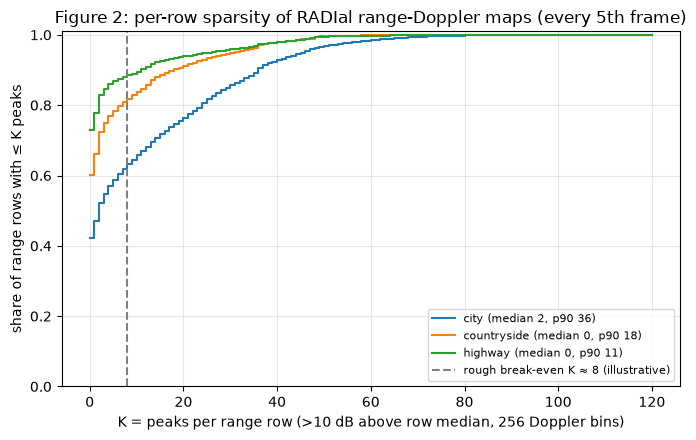

In [135]:
K_rows = dict(np.load("../results/k_rows.npz"))
xs = np.arange(0, 121)                                   # K values 0..120

plt.figure(figsize=(7, 4.5))
for tag, k in K_rows.items():
    ks_sorted = np.sort(k)
    cdf = np.searchsorted(ks_sorted, xs, side="right") / k.size   # share of rows with K <= x
    plt.step(xs, cdf, where="post", label=f"{tag} (median {np.median(k):.0f}, p90 {np.percentile(k, 90):.0f})")

plt.axvline(8, color="gray", linestyle="--", label="rough break-even K ≈ 8 (illustrative)")
plt.xlabel("K = peaks per range row (>10 dB above row median, 256 Doppler bins)")
plt.ylabel("share of range rows with ≤ K peaks")
plt.title("Figure 2: per-row sparsity of RADIal range-Doppler maps (every 5th frame)")
plt.ylim(0, 1.01)
plt.grid(alpha=0.3)
plt.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig("../figures/fig2_row_k_cdf.png", dpi=150)
plt.show()

In [136]:
for tag in SEQS:
    load_seq(tag)
    ks = []
    for n in frames[::STEP]:
        ks.append(row_peaks(frame_to_rd(n), db=6))
    k = np.concatenate(ks)
    print(tag, "6 dB | median", np.median(k), "p90", np.percentile(k, 90),
          "max", k.max(), "rows with K=0:", round(np.mean(k == 0), 3),
          "rows with K<=8:", round(np.mean(k <= 8), 3))

city RECORD@2020-11-21_13.46.26 576
city 6 dB | median 16.0 p90 54.0 max 120 rows with K=0: 0.223 rows with K<=8: 0.399
countryside RECORD@2020-11-22_12.54.38 452
countryside 6 dB | median 6.0 p90 39.0 max 106 rows with K=0: 0.312 rows with K<=8: 0.566
highway RECORD@2020-11-22_12.38.47 388
highway 6 dB | median 1.0 p90 29.0 max 108 rows with K=0: 0.463 rows with K<=8: 0.714


In [139]:
RBIN = 103 / 512                        # metres per range bin

def target_row_k(tag):
    load_seq(tag)
    ch3 = sorted(radar["radar_ch3"])
    lab = labels[(labels["dataset"] == SEQ) & (labels["radar_R_m"] > 0)]
    k_target, k_all = [], []
    for k, grp in lab.groupby("index"):                # one group per labelled frame
        if k >= len(frames) or frames[k] != ch3[k]:
            continue                                   # label-to-frame mapping not trusted here
        kr = row_peaks(frame_to_rd(frames[k]))         # 512 per-row counts, 10 dB
        k_all.append(kr)
        for R in grp["radar_R_m"]:
            r = int(round(R / RBIN))                   # metres -> range bin
            k_target.append(kr[max(r - 1, 0): r + 2].max())
    return np.array(k_target), np.concatenate(k_all)

for tag in SEQS:
    kt, ka = target_row_k(tag)
    print(tag, len(kt), "targets | target rows: median", np.median(kt), "p90", np.percentile(kt, 90),
          "K<=8:", round(np.mean(kt <= 8), 3), "| all rows same frames: median", np.median(ka))

city RECORD@2020-11-21_13.46.26 576
city 5 targets | target rows: median 38.0 p90 46.8 K<=8: 0.0 | all rows same frames: median 10.0
countryside RECORD@2020-11-22_12.54.38 452
countryside 91 targets | target rows: median 36.0 p90 48.0 K<=8: 0.231 | all rows same frames: median 0.0
highway RECORD@2020-11-22_12.38.47 388
highway 32 targets | target rows: median 0.0 p90 0.0 K<=8: 0.969 | all rows same frames: median 0.0


In [140]:
load_seq("highway")
ch3 = sorted(radar["radar_ch3"])
lab = labels[(labels["dataset"] == SEQ) & (labels["radar_R_m"] > 0)]

for k, grp in list(lab.groupby("index"))[:6]:
    if frames[k] != ch3[k]:
        continue
    P = frame_to_rd(frames[k])
    for R in grp["radar_R_m"]:
        r = int(round(R / RBIN))
        print(k, round(R, 1), "m, bin", r)
        print("  10 dB:", row_peaks(P, 10)[r-10:r+11])
        print("   6 dB:", row_peaks(P, 6)[r-10:r+11])

highway RECORD@2020-11-22_12.38.47 388
0 70.0 m, bin 348
  10 dB: [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 13 36 36 29  1]
   6 dB: [ 0  0  0  0  0  0  0  0  0  2  0  0  0  1  1  2 25 36 36 36 15]
1 69.7 m, bin 346
  10 dB: [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 16 36 36 29  5]
   6 dB: [ 0  0  0  0  0  0  0  0  0  0  0  0  0 11 11  0 23 36 36 36 19]
2 69.1 m, bin 343
  10 dB: [ 0  0  0  0  0  0  0  0  0  0  0  2  1  0  0  0  0  9 35 37 33]
   6 dB: [ 0  0  0  0  0  0  0  0  0  0  1  8  5  0  0  0  0 19 39 44 37]
3 68.6 m, bin 341
  10 dB: [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 35 36 36]
   6 dB: [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 12 38 40 43]
4 68.5 m, bin 340
  10 dB: [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  3  3 29 45 42 23]
   6 dB: [ 0  0  0  0  0  0  1  0  0  0  0  0  0  0  1 13 17 38 48 45 25]
5 68.1 m, bin 338
  10 dB: [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 30 39 24 15  2]
   6 dB: [ 0  0  0  0  0  0  0  0  0  0

city RECORD@2020-11-21_13.46.26 576
countryside RECORD@2020-11-22_12.54.38 452
highway RECORD@2020-11-22_12.38.47 388
             offset     K
tag                      
city            3.0  80.0
countryside     0.0  39.0
highway         9.0  36.0


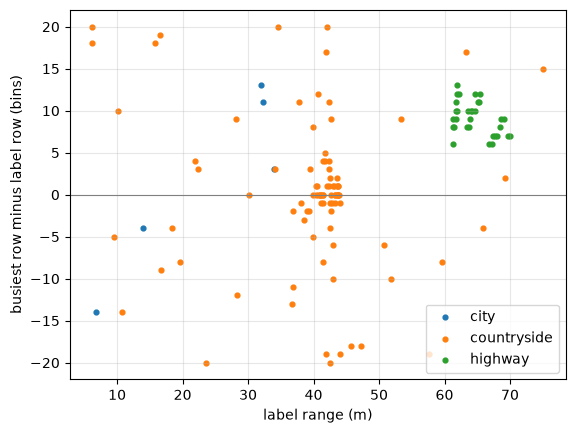

In [141]:
rows = []
for tag in SEQS:
    load_seq(tag)
    ch3 = sorted(radar["radar_ch3"])
    lab = labels[(labels["dataset"] == SEQ) & (labels["radar_R_m"] > 0)]
    for k, grp in lab.groupby("index"):
        if k >= len(frames) or frames[k] != ch3[k]:
            continue
        kr = row_peaks(frame_to_rd(frames[k]))
        for R in grp["radar_R_m"]:
            r = int(round(R / RBIN))
            lo, hi = max(r - 20, 0), min(r + 21, 512)
            best = lo + int(np.argmax(kr[lo:hi]))        # busiest row near the label
            rows.append((tag, R, best - r, kr[best]))

off = pd.DataFrame(rows, columns=["tag", "R", "offset", "K"])
print(off.groupby("tag")[["offset", "K"]].median())

for tag, g in off.groupby("tag"):
    plt.scatter(g["R"], g["offset"], s=12, label=tag)
plt.axhline(0, color="gray", lw=0.8)
plt.xlabel("label range (m)"); plt.ylabel("busiest row minus label row (bins)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [142]:
med = off.groupby("tag")["offset"].transform("median")
clean = off[(off["offset"] - med).abs() <= 5]

print(clean.groupby("tag")["K"].agg(["count", "median", "max", lambda k: np.mean(k <= 8)]))
print(off.groupby("tag")["offset"].median())

             count  median  max  <lambda_0>
tag                                        
city             1    80.0   80         0.0
countryside     55    41.0   69         0.0
highway         32    36.0   48         0.0
tag
city           3.0
countryside    0.0
highway        9.0
Name: offset, dtype: float64
